In [1]:
%pip install -q osmnx pulp

In [2]:
import numpy as np
import pandas as pd
import networkx as nx
import osmnx as ox
import pulp
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

SEED = 42                    # makes the random choices repeatable
P = 3                        # number of emergency stations to place
N_DEMAND = 150               # how many intersections stand in for homes
N_CAND = 60                  # how many intersections could host a station
LEVELS = [0.10, 0.20, 0.30]  # share of road segments to remove
N_REPS = 20                  # repeats of random removal at each level
PLACE = "Paradise, California, USA"

In [3]:
def load_graph():
    G = ox.graph_from_place(PLACE, network_type="drive")
    H = nx.Graph()                          # simple, undirected network
    for u, v, d in G.edges(data=True):
        if u == v:
            continue                        # skip loops
        L = d.get("length", 1.0)
        if H.has_edge(u, v):
            H[u][v]["length"] = min(H[u][v]["length"], L)
        else:
            H.add_edge(u, v, length=L)
    for n in H.nodes():                     # keep coordinates for maps
        H.nodes[n]["x"] = G.nodes[n]["x"]
        H.nodes[n]["y"] = G.nodes[n]["y"]
    keep = max(nx.connected_components(H), key=len)   # largest connected piece
    return H.subgraph(keep).copy()

H_full = load_graph()
print("intersections (nodes):", H_full.number_of_nodes())
print("road segments (edges):", H_full.number_of_edges())

intersections (nodes): 1829
road segments (edges): 1994


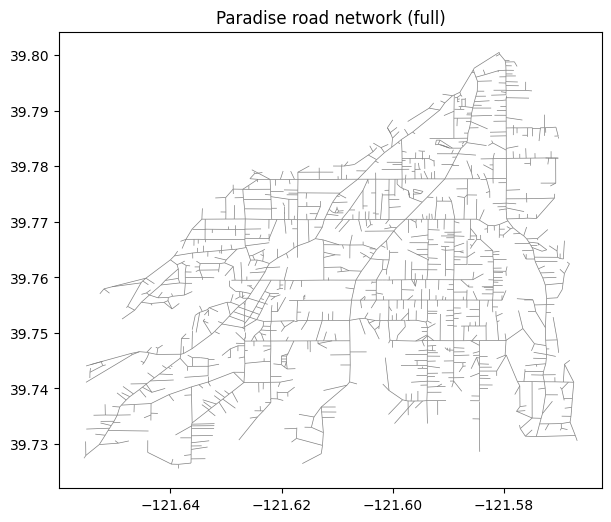

In [4]:
def plot_network(H, demand=None, stations=None, title=""):
    segs = [[(H.nodes[u]["x"], H.nodes[u]["y"]), (H.nodes[v]["x"], H.nodes[v]["y"])]
            for u, v in H.edges()]
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.add_collection(LineCollection(segs, linewidths=0.5, colors="gray"))
    if demand:
        ax.scatter([H.nodes[n]["x"] for n in demand], [H.nodes[n]["y"] for n in demand],
                   s=8, c="tab:blue", label="demand points")
    if stations:
        ax.scatter([H.nodes[n]["x"] for n in stations], [H.nodes[n]["y"] for n in stations],
                   s=200, c="red", marker="*", label="stations")
    ax.autoscale()
    ax.set_aspect("equal")
    ax.set_title(title)
    if demand or stations:
        ax.legend()
    plt.show()

plot_network(H_full, title="Paradise road network (full)")

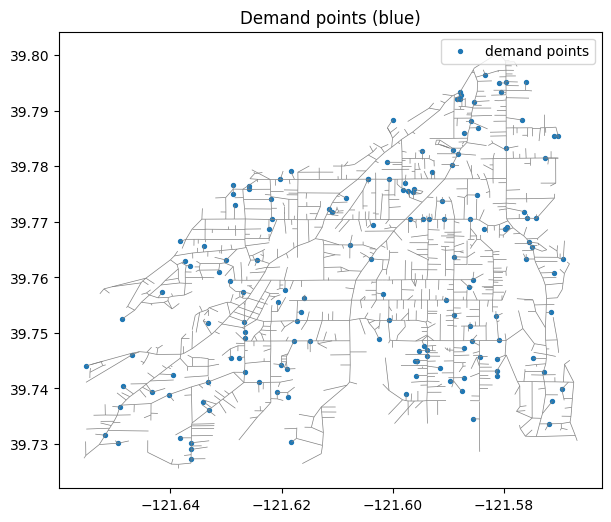

In [5]:
rng = np.random.default_rng(SEED)
nodes = list(H_full.nodes())

dem_idx = rng.choice(len(nodes), N_DEMAND, replace=False)
cand_idx = rng.choice(len(nodes), N_CAND, replace=False)
dem = [nodes[i] for i in dem_idx]     # demand points (stand-ins for homes)
cand = [nodes[i] for i in cand_idx]   # candidate station sites

plot_network(H_full, demand=dem, title="Demand points (blue)")

In [6]:
def dist_matrix(H, cand, dem):
    D = np.full((len(dem), len(cand)), np.inf)      # inf = no route found
    row_of = {n: i for i, n in enumerate(dem)}
    for j, c in enumerate(cand):
        if c not in H:
            continue
        lengths = nx.single_source_dijkstra_path_length(H, c, weight="length")
        for n, d in lengths.items():
            i = row_of.get(n)
            if i is not None:
                D[i, j] = d
    return D

D_full = dist_matrix(H_full, cand, dem)
PENALTY = 2 * D_full.max()      # fixed distance charged when a point cannot reach a site
print("matrix shape (demand points x candidate sites):", D_full.shape)
print("longest distance (m):", round(D_full.max()), "| penalty (m):", round(PENALTY))
pd.DataFrame(D_full[:5, :5]).round(0)

matrix shape (demand points x candidate sites): (150, 60)
longest distance (m): 11701 | penalty (m): 23403


,0,1,2,3,4
0,1446.0,2794.0,4077.0,2212.0,4831.0
1,4445.0,2749.0,8213.0,4233.0,8967.0
2,2619.0,2347.0,7279.0,2407.0,8033.0
3,3002.0,1307.0,6771.0,2790.0,7525.0
4,5632.0,6499.0,4160.0,6397.0,4914.0


In [12]:
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.sparse import coo_matrix, vstack

def solve_pmedian(D, p):
    n_dem, n_cand = D.shape
    n_x = n_dem * n_cand                 # x[i, j]: share of demand point i served by site j
    n_var = n_x + n_cand                 # then y[j]: 1 if site j gets a station
    c = np.concatenate([D.ravel(), np.zeros(n_cand)])   # goal: minimize total distance
    r = np.arange(n_x)
    i_idx = np.repeat(np.arange(n_dem), n_cand)
    j_idx = np.tile(np.arange(n_cand), n_dem)
    # Rule 1: every demand point is fully served
    A1 = coo_matrix((np.ones(n_x), (i_idx, r)), shape=(n_dem, n_var))
    # Rule 2: a point can only be served by a site that has a station (x <= y)
    A2 = coo_matrix((np.concatenate([np.ones(n_x), -np.ones(n_x)]),
                     (np.concatenate([r, r]), np.concatenate([r, n_x + j_idx]))),
                    shape=(n_x, n_var))
    # Rule 3: exactly p stations in total
    A3 = coo_matrix((np.ones(n_cand), (np.zeros(n_cand, dtype=int), n_x + np.arange(n_cand))),
                    shape=(1, n_var))
    A = vstack([A1, A2, A3]).tocsr()
    lb = np.concatenate([np.ones(n_dem), np.full(n_x, -np.inf), [p]])
    ub = np.concatenate([np.ones(n_dem), np.zeros(n_x), [p]])
    integrality = np.concatenate([np.zeros(n_x), np.ones(n_cand)])   # y must be 0 or 1
    res = milp(c, constraints=LinearConstraint(A, lb, ub), integrality=integrality,
               bounds=Bounds(0, 1), options={"time_limit": 120})
    if res.x is None:
        raise RuntimeError("Solver found no solution: " + str(res.message))
    if not res.success:
        print("Warning: solver did not finish cleanly:", res.message)
    return sorted(j for j in range(n_cand) if res.x[n_x + j] > 0.5)

def cost_on(D, chosen):
    # total distance when every demand point uses its nearest chosen station
    return float(D[:, chosen].min(axis=1).sum())

def penalize(D):
    return np.where(np.isfinite(D), D, PENALTY)

Plan A total distance (km): 307.4


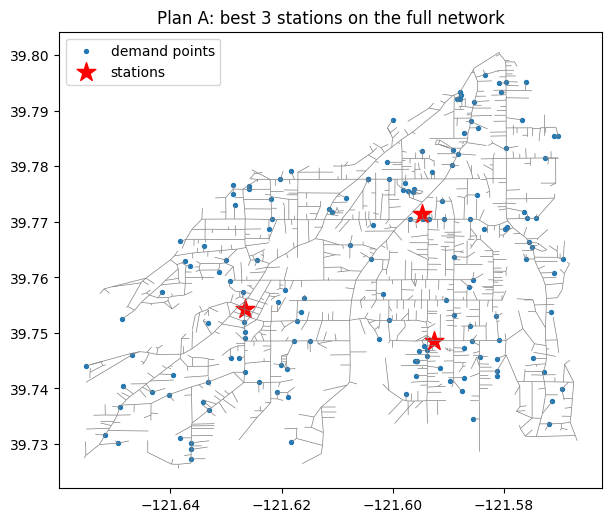

In [13]:
D_full_p = penalize(D_full)
sites_A = solve_pmedian(D_full_p, P)
cost_A = cost_on(D_full_p, sites_A)
print("Plan A total distance (km):", round(cost_A / 1000, 1))
plot_network(H_full, demand=dem, stations=[cand[j] for j in sites_A],
             title="Plan A: best 3 stations on the full network")

In [14]:
rng2 = np.random.default_rng(1)
rand_costs = [cost_on(D_full_p, list(rng2.choice(N_CAND, P, replace=False))) for _ in range(200)]
print("Plan A (km):", round(cost_A / 1000, 1))
print("Average random plan (km):", round(np.mean(rand_costs) / 1000, 1))
print("Best of 200 random plans (km):", round(min(rand_costs) / 1000, 1))

Plan A (km): 307.4
Average random plan (km): 453.7
Best of 200 random plans (km): 342.4


In [15]:
edges_all = list(H_full.edges())
eb = nx.edge_betweenness_centrality(H_full, k=min(300, H_full.number_of_nodes()),
                                    weight="length", seed=SEED)
edges_by_betweenness = sorted(eb, key=eb.get, reverse=True)   # busiest first
print("number of segments:", len(edges_all))

number of segments: 1994


In [16]:
def run_scenario(removed_edges):
    H_miss = H_full.copy()
    H_miss.remove_edges_from(removed_edges)          # the incomplete map
    D_miss = dist_matrix(H_miss, cand, dem)
    n_disc = int((~np.isfinite(D_miss).any(axis=1)).sum())   # points with no route to any site
    sites_B = solve_pmedian(penalize(D_miss), P)     # planner sees only the incomplete map
    cost_B_true = cost_on(D_full_p, sites_B)         # but the choice is judged on the full map
    return {
        "sites_changed": P - len(set(sites_A) & set(sites_B)),
        "regret_pct": 100 * (cost_B_true - cost_A) / cost_A,
        "n_disconnected_demand": n_disc,
    }

In [17]:
rng_demo = np.random.default_rng(0)
k = int(round(0.20 * len(edges_all)))
pick = rng_demo.choice(len(edges_all), k, replace=False)
demo = run_scenario([edges_all[i] for i in pick])
print("Removed", k, "of", len(edges_all), "segments at random")
print(demo)

Removed 399 of 1994 segments at random
{'sites_changed': 1, 'regret_pct': 5.21470390075558, 'n_disconnected_demand': 57}


In [18]:
LEVELS = [0.05, 0.10, 0.20]   # share of road segments removed

rows = []
for level in LEVELS:
    k = int(round(level * len(edges_all)))
    r = run_scenario(edges_by_betweenness[:k])                 # targeted: busiest segments
    rows.append({"mode": "targeted", "level": level, "rep": 0, **r})
    for rep in range(N_REPS):                                  # random: repeated
        pick = rng.choice(len(edges_all), k, replace=False)
        r = run_scenario([edges_all[i] for i in pick])
        rows.append({"mode": "random", "level": level, "rep": rep, **r})
    print("finished level", level)

df = pd.DataFrame(rows)
df.to_csv("pmedian_results.csv", index=False)
df.head()

finished level 0.05
finished level 0.1
finished level 0.2


,mode,level,rep,sites_changed,regret_pct,n_disconnected_demand
0,targeted,0.05,0,2,7.819997,9
1,random,0.05,0,3,31.410827,6
2,random,0.05,1,1,8.811955,14
3,random,0.05,2,2,13.857718,12
4,random,0.05,3,3,24.579108,10


In [19]:
summary = (df.groupby(["mode", "level"])
             .agg(regret_mean=("regret_pct", "mean"), regret_sd=("regret_pct", "std"),
                  sites_changed_mean=("sites_changed", "mean"),
                  disconnected_mean=("n_disconnected_demand", "mean"))
             .round(2))
summary

regret_mean  regret_sd  sites_changed_mean  disconnected_mean
mode     level                                                               
random   0.05         14.19      10.92                1.65              10.15
         0.10         22.88      14.37                2.45              25.45
         0.20         28.80      14.31                2.30              63.45
targeted 0.05          7.82        NaN                2.00               9.00
         0.10         41.24        NaN                3.00              29.00
         0.20         34.72        NaN                3.00              71.00

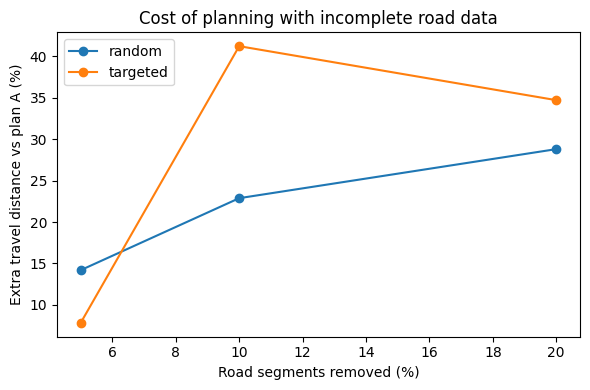

In [20]:
fig, ax = plt.subplots(figsize=(6, 4))
for mode, g in df.groupby("mode"):
    m = g.groupby("level")["regret_pct"].mean()
    ax.plot(m.index * 100, m.values, marker="o", label=mode)
ax.set_xlabel("Road segments removed (%)")
ax.set_ylabel("Extra travel distance vs plan A (%)")
ax.set_title("Cost of planning with incomplete road data")
ax.legend()
plt.tight_layout()
plt.savefig("pmedian_regret.png", dpi=150)
plt.show()

In [21]:
all_rows = []
for seed in [1, 2, 3]:
    rng_s = np.random.default_rng(seed)
    dem = [nodes[i] for i in rng_s.choice(len(nodes), N_DEMAND, replace=False)]
    cand = [nodes[i] for i in rng_s.choice(len(nodes), N_CAND, replace=False)]
    D_full = dist_matrix(H_full, cand, dem)
    PENALTY = 2 * D_full.max()
    D_full_p = penalize(D_full)
    sites_A = solve_pmedian(D_full_p, P)
    cost_A = cost_on(D_full_p, sites_A)
    for level in LEVELS:
        k = int(round(level * len(edges_all)))
        r = run_scenario(edges_by_betweenness[:k])
        all_rows.append({"seed": seed, "mode": "targeted", "level": level, **r})
        for rep in range(10):
            pick = rng_s.choice(len(edges_all), k, replace=False)
            r = run_scenario([edges_all[i] for i in pick])
            all_rows.append({"seed": seed, "mode": "random", "level": level, **r})
    print("finished seed", seed)

df_seeds = pd.DataFrame(all_rows)
df_seeds.to_csv("pmedian_results_other_seeds.csv", index=False)
df_seeds.groupby(["mode", "seed", "level"])["regret_pct"].mean().round(1).unstack("level")

finished seed 1
finished seed 2
finished seed 3


level          0.05  0.10   0.20
mode     seed                   
random   1      9.3  14.7   18.2
         2     11.7  27.0   24.2
         3     10.9  23.6   23.8
targeted 1      4.3  10.1   22.6
         2     10.6  30.8  112.4
         3      6.0  12.8   31.6